# Encapsulation 
- It is the process of wrapping data (variables) and the methods that work on that data (functions) into a single unit called a Class.
- Beyond just "bundling," it also involves Data Hiding—restricting direct access to some of the object's components to prevent accidental or unauthorized modification.
- It also involves Access Control, which means hiding the internal state of an object from the outside world to prevent accidental or malicious interference.
# The Memory Tip: The "Medicine Capsule" 💊
-Think of a Medicine Capsule.

-The powder inside is the data (the medicine).

-The plastic shell is the Class (the capsule).

You don't touch the powder directly; you just swallow the capsule. The shell protects the medicine and ensures it is delivered to your body exactly how it was designed.

In [1]:
class BankAccount:
    def __init__(self, owner, balance):
        self.owner = owner            # Public: Anyone can see/change this
        self.__balance = balance      # Private: The "Double Underscore" hides it

    # Getter: Controlled way to see the balance
    def check_balance(self):
        return f"Account owner: {self.owner} | Balance: ₹{self.__balance}"

    # Setter: Controlled way to change the balance
    def deposit(self, amount):
        if amount > 0:
            self.__balance += amount
            print(f"Successfully deposited ₹{amount}")
        else:
            print("Invalid deposit amount!")

# --- Usage ---
my_acc = BankAccount("Pythesh", 1000)

print(my_acc.owner)        # Works fine
# print(my_acc.__balance)  # CRASHES! Python protects this.

my_acc.deposit(500)        # The proper way to change the balance
print(my_acc.check_balance())

Pythesh
Successfully deposited ₹500
Account owner: Pythesh | Balance: ₹1500


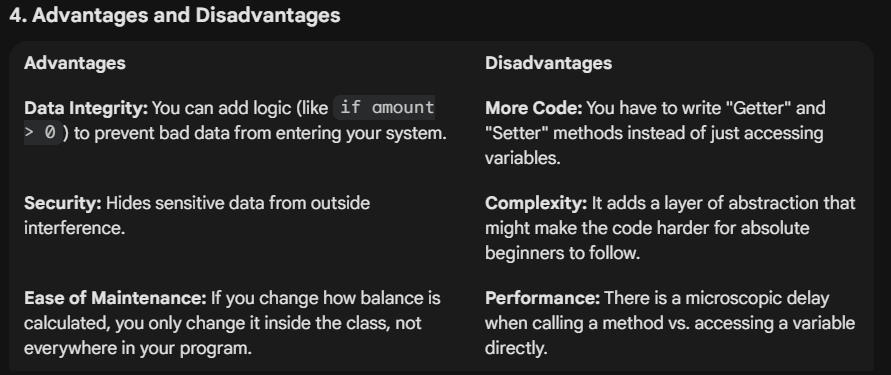

## 5. Best Practices for Pythonistas
- Use @property for Getters/Setters: This is the most "Pythonic" way to do encapsulation. It allows you to access a method like a variable.

- Don't over-encapsulate: If a variable doesn't need protection (like a color attribute), just leave it public.

- The "Single Underscore" Convention: Use _variable for internal data that isn't strictly "locked" but is a signal to other devs saying, "Please don't touch this unless you know what you're doing."


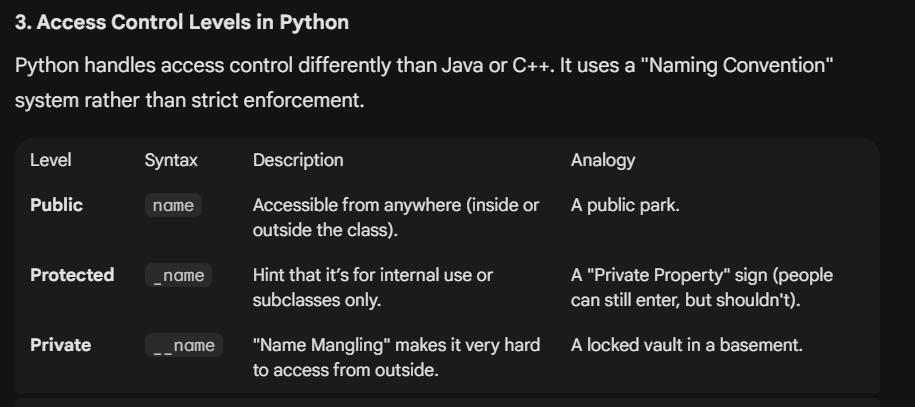

# Access Modifiers:
## **1. Public Access Modifier:**
- Variables and methods defined without any underscores. They are accessible from anywhere—inside the class, outside the class, and in subclasses.

Example:
```Python
class Hero:
    def __init__(self, name):
        self.name = name  # Public variable

h = Hero("Iron Man")
print(h.name) # Accessible directly
```

### 💡 5 Tips to Remember:

The Default: If you don't add underscores, it is automatically public.

The "Open Door": Use it for data that is safe for anyone to see or change.

No Protection: Anyone can write h.name = "Trash Can" and ruin your object.

API Ready: Public methods are the primary way users interact with your code.

Keep it Slim: Don't make everything public; only expose what is necessary.

## __2. Protected Access Modifier ( _ ) :__
- Variables defined with a single underscore. This is a "Gentleman's Agreement" or a hint to other programmers that the variable is intended for internal use and within subclasses.

Example:
``` Python
class Parent:
    def __init__(self):
        self._treasure = "Family Gold" # Protected

class Child(Parent):
    def reveal(self):
        print(self._treasure) # Subclasses can use it comfortably
```
### 💡 5 Tips to Remember:

The "Internal Only" Sign: It says: "You can touch this, but you probably shouldn't."

**Inheritance Friendly: Use this when you want child classes to inherit the data.**

Not Enforced: Python will not stop you from accessing obj._treasure from outside.

Library Standard: Most Python libraries use this to hide "under-the-hood" logic.

Maintenance Warning: If you change a protected variable, you might break child classes.

## **3. Private Access Modifier ( __ ):**
- Variables defined with a double underscore. This triggers Name Mangling, where Python internally changes the variable name to make it much harder to access from outside the class.

Example:
```Python
class Vault:
    def __init__(self):
        self.__passcode = 1234 # Private

v = Vault()
# print(v.__passcode) # ❌ This will crash (AttributeError)
```
### 💡 5 Tips to Remember:

The "Vault": Use this for extremely sensitive data (passwords, raw balances).

Name Mangling: Python renames __passcode to _Vault__passcode behind the scenes.

Strict Scope: Even subclasses cannot easily access these variables.

Conflict Prevention: Use this to prevent name clashes if a subclass has a variable with the same name.

Not Bulletproof: A developer can still "hack" it using the mangled name, but it prevents accidental access.

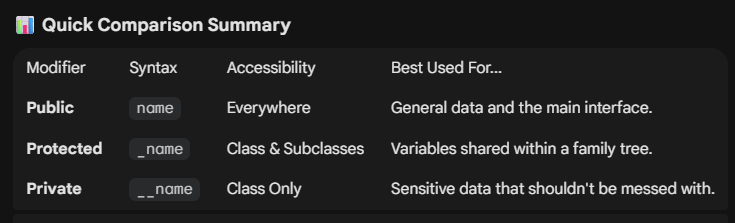

In [ ]:
class Home:
    def __init__(self,remote,bedremote):
        self.remote = remote
        self.__bedremote = bedremote
    def hall(self):
        return f"Hey this is accessible by everyone in the house {self.remote}!!!"
    def bedrm(self):
        return f"Hey this {self.__bedremote} is not accessible by everyone in the house except the bedroom owner's"
#     def accessbedrm(self):
#         return self.__bedremote
v = Home("samsung remote","lg remote")
print(v.hall())
print(v.bedrm())

dir(v)
print(v._Home__bedremote) # Private variable

Hey this is accessible by everyone in the house samsung remote!!!
Hey this lg remote is not accessible by everyone in the house except the bedroom owner's
lg remote


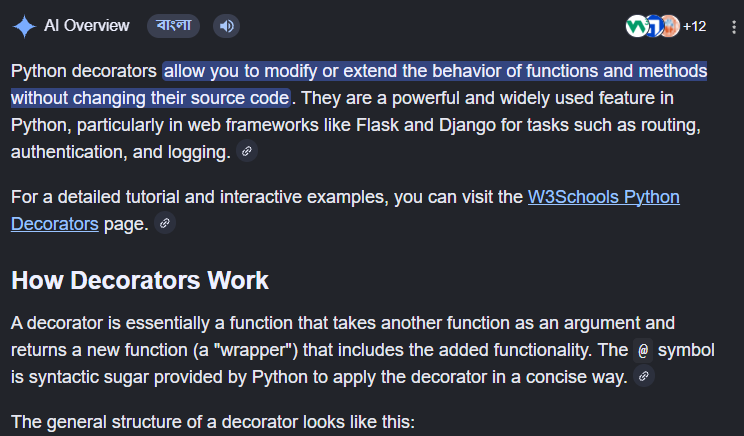

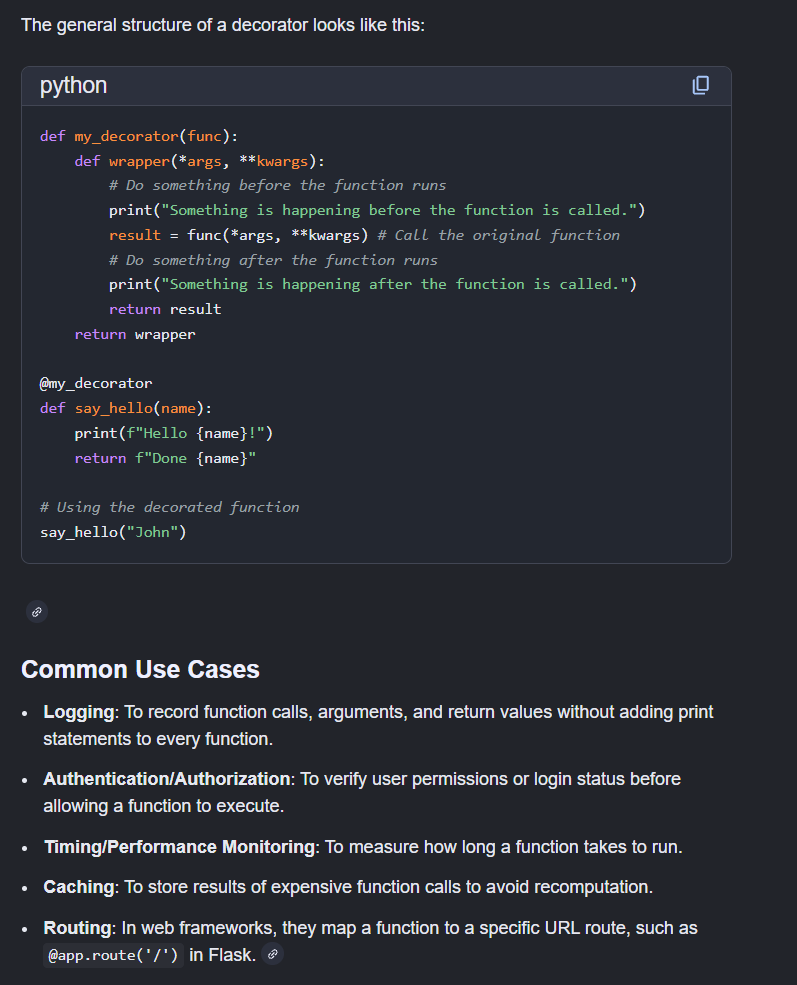

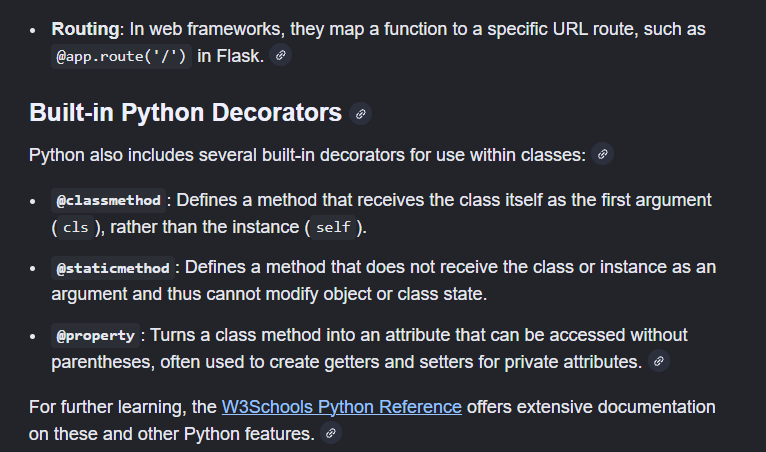

In [ ]:
# Lets Demonstrate the Decorators in Python

class Employee:
    def __init__(self, firstnaam,lastnaam):
        self.firstnaam = firstnaam
        self.lastnaam = lastnaam
        self.email = self.firstnaam + '.' + self.lastnaam + '@email.com'

    def fullname(self):
        return '{1} {0}'.format(self.firstnaam,self.lastnaam) # remeber this f string concatination based on the postion of format(attributes) order
    
e1 = Employee('Krithin','Vardha')
print("Email as the user created first time: ",e1.email)
e1.fullname() # calling full name function!!


e1.firstnaam = "Karthik" # changing the name is not working effectively for same object "e1"

print("Email after name change:",e1.email) #not working
e1.fullname()


''' 
The self.email is not updating because it is a static instance attribute assigned only once during the object's creation (__init__). 

When you create e1 = Employee('Krithin', 'Vardha'), Python evaluates self.firstnaam + '.' + self.lastnaam + '@email.com' one time,
 resulting in "Krithin.Vardha@email.com". Even when you update e1.firstnaam = 'Karthik', the self.email variable still holds the string that was computed during initialization. 

'''

Email as the user created first time:  Krithin.Vardha@email.com
Email after name change: Krithin.Vardha@email.com


'Vardha Karthik'

In [44]:
# Lets resolve the above issue using @ decorators
# How to Fix It (Using Decorators)
# To make self.email update automatically, you should turn it into a property. 
# This computes the email address on-the-fly every time you access it, rather than storing it once.
class Employee:
    def __init__(self, firstnaam, lastnaam):
        self.firstnaam = firstnaam
        self.lastnaam = lastnaam
        # self.email = ... # Removed: No longer pre-computing

    @property
    def email(self):
        # Computed dynamically every time email is accessed
        return "{}.{}@email.com".format(self.firstnaam, self.lastnaam)
    @property
    def fullname(self):
        return "{1} {0}".format(self.firstnaam, self.lastnaam)
    @fullname.setter
    def fullname(self,name):
        first , last = name.split(' ')
        self.firstnaam = first
        self.lastnaam = last
    
    @fullname.deleter
    def fullname(self):
        print("Idigo Delete ayipoyindi!!")
        self.firstnaam = None
        self.lastnaam = None

e1 = Employee('Krithin', 'Vardha')

e1.fullname = "Krithin V" # this change will update only when the function is made as decorator and setter with the func naam 
# Accessing e1.email calls the property function
print("Email as the user created first time:", e1.email,"of",e1.firstnaam) 

# Changing the name
e1.firstnaam = 'Karthik'

# Email updates automatically
print("Email after name change:", e1.email)

del e1.fullname # del to call a deleter functions that we created!!

# print(e1.firstnaam)


Email as the user created first time: Krithin.V@email.com of Krithin
Email after name change: Karthik.V@email.com
Idigo Delete ayipoyindi!!


#  @property 
- It is a built-in, special-purpose decorator specifically designed to turn a method into a "getter" for a read-only attribute. 
- It is not merely an arbitrary keyword, but rather part of the fundamental syntax and structure of the language designed for this specific use case. 

### You can certainly use other keywords and names for custom decorators. Python's decorator system is flexible.
### Here's why @property exists and what alternatives you have: 

**Why @property?**
- The @property decorator provides "syntactic sugar" for managing attribute access. 
- Clarity and Readability: It makes the code more readable by clearly indicating that a method is actually a property and can be accessed without calling it (i.e., instance.attribute instead of instance.attribute()).
- Encapsulation: It allows you to implement getter, setter, and deleter methods for attributes in a clean, Pythonic way, enabling you to add logic (like validation) when an attribute is accessed or modified without  changing the external interface of the class.
- A Core Language Feature: It is a key feature of Python's object-oriented capabilities, providing a standard way to implement controlled access. 

### **Why not any other keyword?**
- While you cannot replace the keyword **property** with something else like **@attribute** and expect it to work in the same built-in capacity, you can create and use other custom decorators with different names. 
- Python's decorator mechanism allows you to define your own functions that take another function or method as an argument and return a new, modified function or method. 
- Here is a brief example of a custom decorator:

### In this example, @my_custom_decorator is the "keyword" used to apply the decorator's logic to the say_hello function.


**In summary:** You must use @property for the specific functionality it provides (turning a method into an attribute). For all other purposes, you are free to define and use custom decorators with whatever names you choose.

In [34]:
def my_custom_decorator(say_hello):
    def wrapper():
        print("Something is happening before the function is called.")
        say_hello()
        print("Something is happening after the function is called.")
    return wrapper

@my_custom_decorator
def say_hello():
    print("Hello!")

say_hello()


Something is happening before the function is called.
Hello!
Something is happening after the function is called.


In [ ]:
# In Python, the Getters and Setters pattern is the "Professional" way to handle encapsulation. 
# It allows you to protect your data while making it feel like a normal variable to the person using your code.

class Smartphone:
    def __init__(self, model):
        self.model = model
        self.__battery = 50  # Private variable

    # 1. THE GETTER (The Reader)
    @property
    def battery(self):
        print(f"Checking battery for {self.model}...")
        return f"{self.__battery}%"

    # 2. THE SETTER (The Security Guard)
    @battery.setter
    def battery(self, value):
        if 0 <= value <= 100:
            print(f"Setting battery to {value}...")
            self.__battery = value
        else:
            print("❌ Error: Invalid battery level! Must be 0-100.")

# --- Using the class ---
my_phone = Smartphone("iPhone 15")

# Notice: We don't use () even though 'battery' is a function!
print(my_phone.battery)  # Calls the @property (Getter)

my_phone.battery = 85    # Calls the @battery.setter (Setter)
print(my_phone.battery)

my_phone.battery = 500   # Triggers the error check in the setter

Checking battery for iPhone 15...
50%
Setting battery to 85...
Checking battery for iPhone 15...
85%
❌ Error: Invalid battery level! Must be 0-100.


## Effective Tips for @property
- Getter First: You must define the @property (getter) before you can define the .setter.

- Same Names: The name of the getter and setter methods must be exactly the same (e.g., def battery).

- Encapsulation Trick: Name your internal variable with a double underscore (like self.__battery) so people are forced to use your "Guard" (the setter).

- No Parentheses: Remember, when using @property, you call it like phone.battery, not phone.battery().

- Read-Only Power: If you want a variable that can be seen but never changed, just write the @property part and skip the @setter entirely.